In [2]:
%pip install geopandas
%matplotlib inline

import geopandas as gpd
import pandas as pd

Note: you may need to restart the kernel to use updated packages.


In [4]:
evictions = pd.read_csv("../../w6/input/Evictions_20240615.csv")

evictions.head()

,Court Index Number,Docket Number,Eviction Address,Eviction Apartment Number,Executed Date,Marshal First Name,Marshal Last Name,Residential/Commercial,BOROUGH,Eviction Postcode,Ejectment,Eviction/Legal Possession,Latitude,Longitude,Community Board,Council District,Census Tract,BIN,BBL,NTA
0,318594/23,14150,172 WEST 107TH ST,1W,01/04/2024,David,Smith,Residential,MANHATTAN,10025,Not an Ejectment,Possession,40.800704,-73.964267,7.0,7.0,193.0,1055977.0,1.018610e+09,Morningside Heights
1,016134/18,86658,70 BRUCKNER BLVD.,12E,11/29/2018,Henry,Daley,Residential,BRONX,10454,Not an Ejectment,Possession,40.806321,-73.926264,1.0,8.0,19.0,2116953.0,2.022950e+09,Mott Haven-Port Morris
2,300816/222,209993,23 WYONA STREET,NaN,11/30/2022,Richard,Capuano,Residential,QUEENS,11207,Not an Ejectment,Possession,40.678696,-73.894650,5.0,37.0,1146.0,3389505.0,3.036630e+09,Cypress Hills-City Line
3,K52673/17,94663,601 BRIGHTON BEACH A VE,FRONT GROUND STORE,04/12/2017,Darlene,Barone,Commercial,BROOKLYN,11235,Not an Ejectment,Possession,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,79638/19,173756,540 NEW LOTS AVE,1R,01/18/2024,Alfred,Locascio,Residential,BROOKLYN,11207,Not an Ejectment,Possession,40.663958,-73.888289,5.0,42.0,1122.0,3096753.0,3.043040e+09,East New York (Pennsylvania Ave)


In [5]:
# set data type
evictions["Executed Date"] = pd.to_datetime(evictions["Executed Date"])

#make a new df with just 2024 entries
evictions_2024 = evictions[(evictions["Executed Date"] >= "2024-01-01") & (evictions["Executed Date"] <= "2024-12-31")]

In [8]:
evictions_2024.dtypes

Court Index Number                   object
Docket Number                         int64
Eviction Address                     object
Eviction Apartment Number            object
Executed Date                datetime64[ns]
Marshal First Name                   object
Marshal Last Name                    object
Residential/Commercial               object
BOROUGH                              object
Eviction Postcode                     int64
Ejectment                            object
Eviction/Legal Possession            object
Latitude                            float64
Longitude                           float64
Community Board                     float64
Council District                    float64
Census Tract                        float64
BIN                                 float64
BBL                                 float64
NTA                                  object
dtype: object

In [ ]:
zip_count = evictions_2024.groupby("Eviction Postcode").size().reset_index(name="Count")

zip_count.head()

,Eviction Postcode,Count
0,0,1
1,200,1
2,10001,39
3,10002,45
4,10003,23


<Axes: >

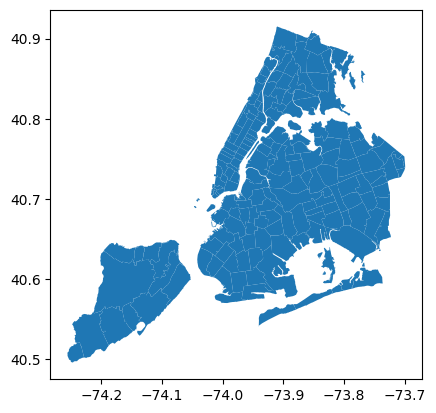

In [17]:
zip_codes = gpd.read_file("nyc-zip-code-tabulation-areas-polygons.geojson")

zip_codes.plot()

In [19]:
zip_count["Eviction Postcode"] = zip_count["Eviction Postcode"].astype(str)

zip_totals = zip_codes.merge(
    zip_count,
    left_on="postalCode",
    right_on="Eviction Postcode"
)

Text(0.5, 1.0, '2024 NYC Evictions by ZIP Code')

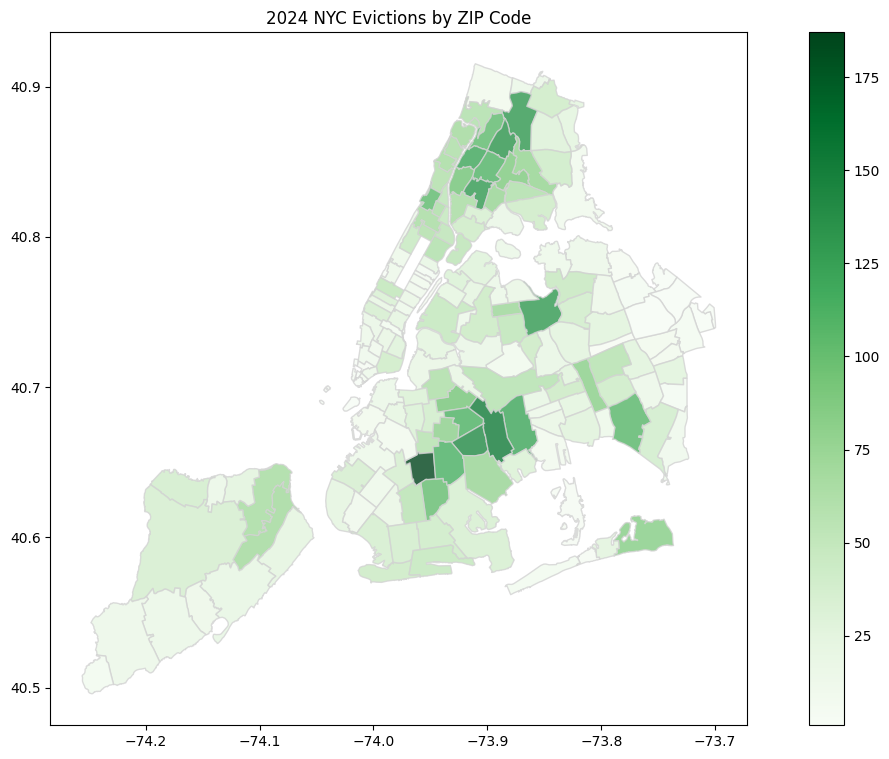

In [21]:
ax = zip_totals.plot(
    column="Count",
    cmap="Greens",
    figsize=(16, 9),
    alpha=0.8,
    legend=True,
    edgecolor="lightgray"
)
ax.set_title("2024 NYC Evictions by ZIP Code")
